In [1]:
import numpy as np
import json
import os
import sys
import matplotlib.pyplot as plt
import scienceplots  # optional, requires latex
plt.style.use(['science', 'grid'])
import jax
from jax import numpy as jnp

# Import plotting utility functions
sys.path.append('../')
from plot_util import (init_metrics, update_metrics, init_variables, update_variables,
                       plot_field, plot_field_residual, plot_field_columns, make_formatter, subsample_steps, pcolor_plot,
                        animate_frame, moving_average, moving_min)

In [145]:
# Select run to plot
results_folder = r"results"

measurments_type = ["displacement","strain"][0]
material_law = ["isotropic","orthotropic"][1]
dic_measurments = 0
iteration = 310000
time = 10
n_measurments = 25
noise = 1e-06
dic_prefix = 'dic_' if dic_measurments else '' 
run_number = 2

run = f"{material_law}_{measurments_type}_{n_measurments}x{n_measurments}_{noise}noise_{time if time else iteration}{'min' if time else 'iter'}{f'-{run_number}' if run_number else ''}"
run_folder = os.path.join(results_folder, run)+"/"
print(f"Run: {run}")

Run: orthotropic_displacement_25x25_1e-06noise_10min-2


In [146]:
# Load Configuration and Data

with open(os.path.join(run_folder, "config.json")) as f:
    run_config = json.load(f)

def read_data_file(filename):
    with open(filename, "r") as f:
        steps = []
        values = []
        for line in f.readlines():
            step, value = line.strip().split(' ', 1)
            steps.append(eval(step))
            values.append(eval(value))
    return steps, values

# Load loss and variable history data
loss_history = np.loadtxt(os.path.join(run_folder, "loss_history.dat"))
# loss_history_mean = moving_average(loss_history, 20)
# loss_history_min = moving_min(loss_history, 20)
variables_history = read_data_file(os.path.join(run_folder, "variables_history.dat"))

# Compute different metrics
residuals = loss_history[:, -1]
PDE_loss = np.mean(loss_history[:, 1:3], axis=1)
Mat_loss = np.mean(loss_history[:, 3:5], axis=1)
DIC_loss = np.mean(loss_history[:, 5:7], axis=1)
steps_loaded = loss_history[:, 0]

# Extract material parameters from config
params_names = run_config["problem"]["params_names"]
params_init = run_config["problem"]["params_init"] #/ 1e3  # Convert to GPa: 1e3 N/mm^2 = 1 GPa
params_actual = run_config["problem"]["params_actual"] #/ 1e3  # Convert to GPa: 1e3 N/mm^2 = 1 GPa


params_history = [np.array(variables_history[1])[:len(steps_loaded), i] for i in range(len(params_init))]

metrics = [residuals, PDE_loss, Mat_loss, DIC_loss]
metrics_names = ["Rel. l2 error", "PDE Loss", "Material Loss", "DIC Loss"]

GPA_unit = True
if GPA_unit:
    for i in range(len(params_init)):
        if "E" in params_names[i] or "G" in params_names[i]:
            params_init[i] /= 1e3
            params_actual[i] /= 1e3
            params_history[i] = params_history[i] / 1e3
    # params_names = [name + " (GPa)" if ("E" in name or "G" in name) else name for name in params_names]

if material_law == "isotropic":
    params_names_tex = [r"$E$", r"$\nu$"]
else:
    params_names_tex = [r"$E_{11}$", r"$E_{22}$", r"$G_{12}$", r"$\nu_{12}$"]

# Configure x-axis based on iterations or elapsed time
step_type = "time"  # or "iteration"
time_unit = "min"   # or "s"
t_elapsed = run_config["execution"]["elapsed"]
if step_type == "time":
    steps = np.array(steps_loaded) * t_elapsed / steps_loaded[-1]
    if time_unit == "min":
        steps = steps / 60
else:
    steps = steps_loaded

In [147]:
colors = plt.get_cmap('tab10').colors
def init_variables(ax, steps, params_actual, params_history, params_name):
    """
    Initialize parameter evolution plots on given axe.
    """
    line_params = [ax.plot([], [], color=colors[i % len(colors)], zorder=3)[0] for i in range(len(params_history))]
    scatter_params = [ax.scatter([], [], zorder=4, label=f"{params_names[i]} = {params_history[0][i]:.3f}",color=colors[i % len(colors)]) for i in range(len(params_history))]
    for i, param in enumerate(params_history):
        ax.hlines(y=params_actual[i], xmin=0, xmax=np.max(steps), linestyles='-.', colors=colors[i % len(colors)])
        ax.plot(steps, param, color=colors[i % len(colors)], alpha=0.2)
    for i, name in enumerate(params_name):
        scatter_params[i].set_label(f"{name} = {params_history[0][i]:.3f}")
    ax.legend()

    return line_params, scatter_params, ax
    
    # ax.hlines(y=param1_actual, xmin=0, xmax=np.max(steps), linestyles='-.', colors="b")
    # axs[1].hlines(y=param2_actual, xmin=0, xmax=np.max(steps), linestyles='-.', colors="r")
    # line_param1, = axs[0].plot([], [], color='b', zorder=3)
    # line_param2, = axs[1].plot([], [], color='r', zorder=3)
    # axs[0].plot(steps, param1_history, color='b', alpha=0.2)
    # axs[1].plot(steps, param2_history, color='r', alpha=0.2)
    # scatter_param1 = axs[0].scatter([], [], c='k', zorder=4,
    #                              label=f"{param2_name} = {param2_history[0]:.3f}")#|{param2_actual:.3f}")
    # scatter_param2 = axs[1].scatter([], [], c='k', zorder=4,
    #                              label=f"{param2_name} = {param2_history[0]:.3f}")#|{param2_actual:.3f}")
    # axs[0].legend()
    # axs[1].legend()
    # return line_param1, line_param2, scatter_param1, scatter_param2, ax

def update_variables(iteration, line_params, scatter_params, ax,
                     steps, params_history, params_actual, params_name):
    """
    Update the parameter evolution plots for the given iteration.

    """
    for i, line_param in enumerate(line_params):
        line_param.set_data(steps[:iteration+1], params_history[i][:iteration+1])
        scatter_params[i].set_offsets([steps[iteration], params_history[i][iteration]])
        scatter_params[i].set_label(f"{params_name[i]} = {params_history[i][iteration]:.3f}")
    ax.legend()
    return line_params, scatter_params, ax

    # line_param1.set_data(steps[:iteration+1], param1_history[:iteration+1])
    # scatter_param1.set_offsets([steps[iteration], param1_history[iteration]])
    # scatter_param1.set_label(f"{param1_name} = {param1_history[iteration]:.1f}")# | {param1_actual:.1f}")
    
    # line_param2.set_data(steps[:iteration+1], param2_history[:iteration+1])
    # scatter_param2.set_offsets([steps[iteration], param2_history[iteration]])
    # scatter_param2.set_label(f"{param2_name} = {param2_history[iteration]:.3f}")# | {param2_actual:.3f}")

    
    # axs[0].legend()
    # axs[1].legend()
    # return line_param1, line_param2, scatter_param1, scatter_param2, axs

Parameter      Initial        Final          Reference      Rel. Error (%) 
E1             157.50         209.97         210.00         0.013          
E2             157.50         102.53         105.00         2.354          
G12            50.00          78.29          80.00          2.134          
nu12           0.20           0.30           0.30           0.141          


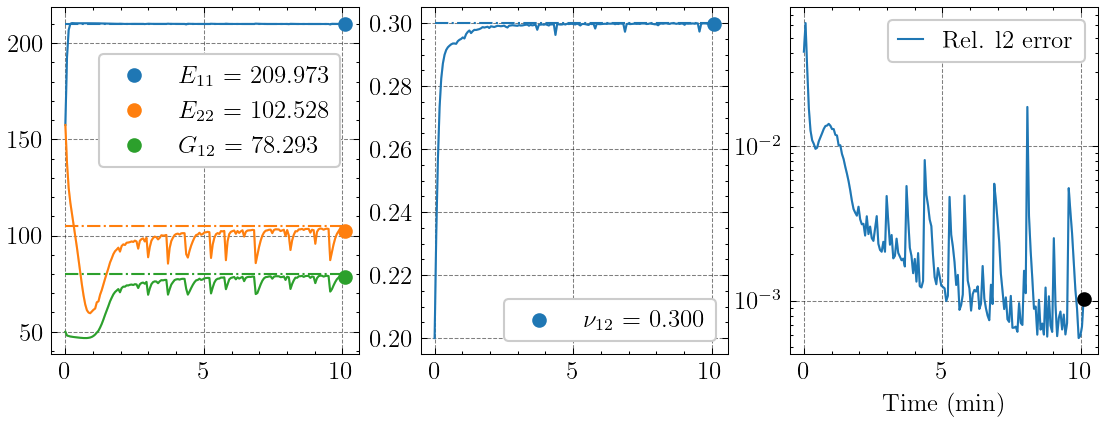

In [148]:
# Plot Metrics and Parameter Evolution

iteration = len(steps) - 1
# --- Plot Metrics ---
# fig, ax_metric = plt.subplots(1, 1, figsize=(3, 3), dpi=100)
# lines, scatters = init_metrics(ax_metric, steps, metrics, metrics_names, step_type=step_type, time_unit=time_unit, metrics_idx=[0])
# update_metrics(iter, lines, scatters, steps, metrics, metrics_idx=[0])
# plt.show()

# --- Plot Parameter Evolution ---
# fig, axs_vars = plt.subplots(2, 1, figsize=(3, 6), dpi=100)
# line_E, line_nu, scatter_E, scatter_nu, axs_vars = init_variables(
#     axs_vars, steps, E_actual, nu_actual, E_history, nu_history, E_name, nu_name)
# update_variables(iter, line_E, line_nu, scatter_E, scatter_nu,
#                  axs_vars, steps, E_history, nu_history, E_actual, nu_actual, E_name, nu_name)
# plt.show()

# --- Print Final Parameter Values ---
# E_final = np.mean(E_history[-10:])
# nu_final = np.mean(nu_history[-10:])
print(f"{'Parameter':<15}{'Initial':<15}{'Final':<15}{'Reference':<15}{'Rel. Error (%)':<15}")
for i, name in enumerate(params_names):
    print(f"{name:<15}{params_init[i]:<15.2f}{params_history[i][-1]:<15.2f}{params_actual[i]:<15.2f}{(abs(params_history[i][-1] - params_actual[i]) / params_actual[i] * 100):<15.3f}")
# print(f"{'E (GPa)':<15}{E_init:<15.2f}{E_final:<15.2f}{E_actual:<15.2f}{(abs(E_final - E_actual) / E_actual * 100):<15.3f}")
# print(f"{'nu':<15}{nu_init:<15.4f}{nu_final:<15.4f}{nu_actual:<15.4f}{(abs(nu_final - nu_actual) / nu_actual * 100):<15.3f}")

# --- Combined Plot ---
fig, axs_combined = plt.subplots(1, 3, figsize=(9, 3), dpi=150)
lines, scatters = init_metrics(axs_combined[-1], steps, metrics, metrics_names, step_type=step_type, time_unit=time_unit, metrics_idx=[0])
update_metrics(iteration, lines, scatters, steps, metrics, metrics_idx=[0])

ax_vars = [None, None]
line_params = [None, None]
scatter_params = [None, None]
# for i in range(2):

line_params[0], scatter_params[0], ax_vars[0] = init_variables(
    axs_combined[0], steps, params_actual[0:3], params_history[0:3], params_names_tex[0:3])
update_variables(iteration, line_params[0], scatter_params[0], ax_vars[0],
                steps, params_history[0:3], params_actual[0:3], params_names_tex[0:3])
ax_vars[0].legend(loc='upper right', bbox_to_anchor=(0.98, 0.9))

line_params[1], scatter_params[1], ax_vars[1] = init_variables(
    axs_combined[1], steps, params_actual[3:], params_history[3:], params_names_tex[3:])
update_variables(iteration, line_params[1], scatter_params[1], ax_vars[1],
                steps, params_history[3:], params_actual[3:], params_names_tex[3:])

# line_params, scatter_params, ax_vars = init_variables(
#     axs_combined[0], steps, params_actual, params_history, params_names)
# update_variables(iteration, line_params, scatter_params, ax_vars,
#                    steps, params_history, params_actual, params_names)
plt.show()

In [149]:
# Load Field Data
field_names = run_config["network"]["logged_fields"]
fields_loaded = [0, 1, 2, 3, 4, 5, 6, 7] # 0: ux, 1: uy, 2: exx, 3: eyy, 4: exy to be loaded
fields_plotted = [0, 1, 2, 6, 7]#[:2]

fields = [None] * 8
for fid in fields_loaded:
    field_name = field_names[fid]
    _, V_pinn = read_data_file(os.path.join(run_folder, f"{field_name}_history.dat"))
    fields[fid] = np.array(V_pinn)

In [150]:
import matplotlib.colors as mcolors
import matplotlib.transforms as mtransforms

def plot_field_columns(fig, ax, fields, fields_id, iteration, Xgrid, Ygrid,
                       func, field_names, colormap, make_formatter):
    """
    Plot exact, computed, and residual fields (with colorbars) for each field.

    Parameters:
      - fig: matplotlib figure
      - ax: 2D array of axes with shape (3, 1+n_fields)
      - fields: list (or dict) of field data
      - fields_id: list of field ids to plot
      - iteration: current iteration index
      - Xmesh, Ymesh: meshgrid arrays for plotting (edges, n+1 x n+1)
      - Xgrid, Ygrid: meshgrid arrays for evaluation (centers, n x n)
      - func: function returning the exact field (used to compute field differences)
      - field_names: list of field names
      - colormap: colormap to use
      - make_formatter: function to create scalar formatter for colorbars

    Returns:
      (ims_ref, ims_field, ims_res)
    """
    ims_ref, ims_field, ims_res = [], [], []

    # Flatten evaluation grid for model calls
    eval_points = np.hstack((Xgrid.reshape(-1, 1), Ygrid.reshape(-1, 1)))
    fields_exact_all = func(eval_points).reshape(Xgrid.shape + (-1,))

    for i, field_id in enumerate(fields_id):
        # --- Exact solution (top row) ---
        ax_exact = ax[0][i]
        field_exact = fields_exact_all[..., field_id]
        field_norm = mcolors.Normalize(vmin=field_exact.min(), vmax=field_exact.max())
        im_ref = pcolor_plot(ax_exact, Xgrid, Ygrid, field_exact, field_names[field_id] + "*",
                             colormap=colormap, norm=field_norm)
        ims_ref.append(im_ref)

        # Colorbar for exact
        pos = ax_exact.get_position()
        cax_pos = mtransforms.Bbox.from_bounds(pos.x0 + pos.width*0.05, pos.y1 + 0.04,
                                               pos.width*0.9, 0.01)
        cax = fig.add_axes(cax_pos)
        cbfield = fig.colorbar(im_ref, cax=cax, orientation='horizontal', format=make_formatter())
        cbfield.ax.xaxis.set_ticks_position('top')

        # --- Predicted field (middle row) ---
        ax_field = ax[1][i]
        field_pred = np.array(fields[field_id][iteration]).reshape(Xgrid.shape)
        im_field = pcolor_plot(ax_field, Xgrid, Ygrid, field_pred, field_names[field_id],
                               colormap=colormap, norm=field_norm)
        ims_field.append(im_field)

        # --- Residual (bottom row) ---
        ax_res = ax[2][i]
        field_diff = field_pred - field_exact
        diff_norm = mcolors.Normalize(vmin=-np.abs(field_diff).max(), vmax=np.abs(field_diff).max())
        im_res = pcolor_plot(ax_res, Xgrid, Ygrid, field_diff, f"{field_names[field_id]}-{field_names[field_id]}*",
                             colormap='coolwarm', norm=diff_norm)
        ims_res.append(im_res)

        pos = ax_res.get_position()
        cax_pos = mtransforms.Bbox.from_bounds(pos.x0 + pos.width*0.05, pos.y0 - 0.03,
                                               pos.width*0.9, 0.01)
        cax = fig.add_axes(cax_pos)
        fig.colorbar(im_res, cax=cax, orientation='horizontal', format=make_formatter())

    return ims_ref, ims_field, ims_res


Fig width: 18.0, set it to 6.00 < 6.34 (A4 with margins) in latex to have a printed font size of 6 for titles and 4.00 for the axis


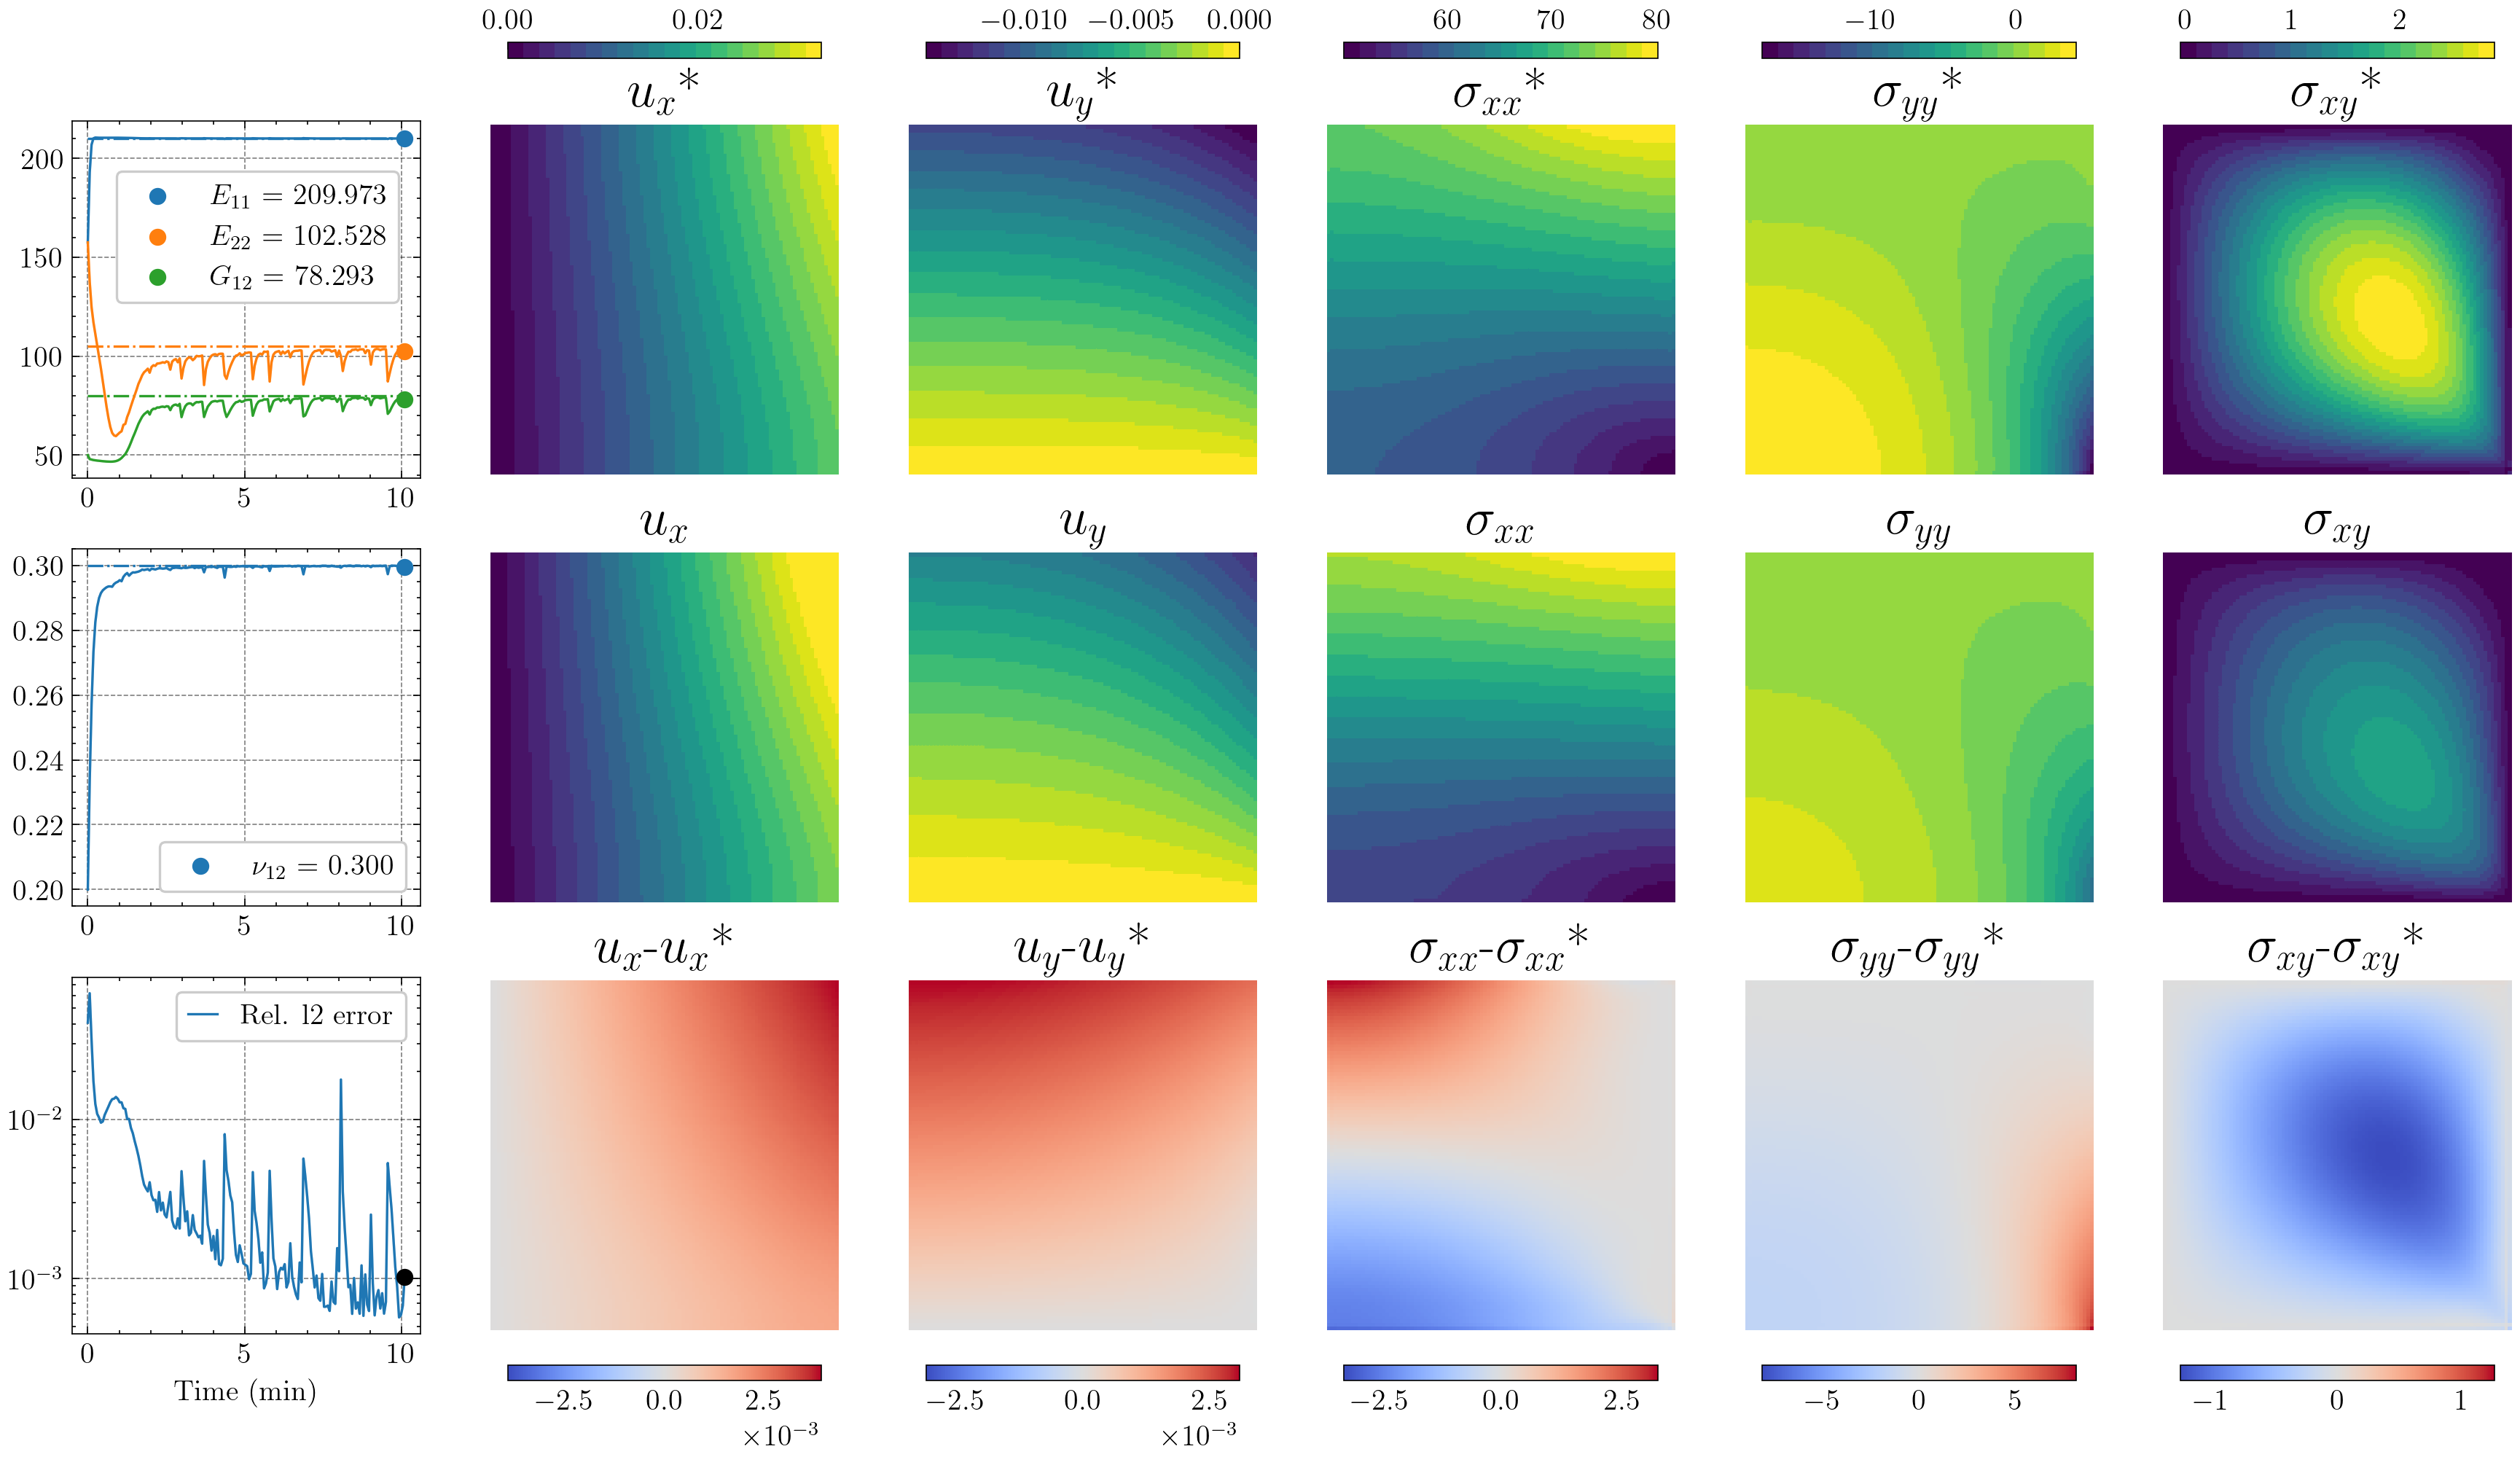

In [151]:
# Field Plotting
import matplotlib.colors as mcolors
from scipy.interpolate import RegularGridInterpolator

# --- Font size for printing ---
plotting_factor = 3
font_factor = 3
title_font_size = 6
axes_font_size = 4
plt.rcParams.update({
    "font.size": title_font_size*font_factor,         # Default font size for all text
    "figure.titlesize": title_font_size*font_factor, 
    "axes.labelsize": axes_font_size*font_factor,
    "xtick.labelsize": axes_font_size*font_factor,
    "ytick.labelsize": axes_font_size*font_factor,
    "legend.fontsize": axes_font_size*font_factor,
})

field_names_tex = [r"$u_x$", r"$u_y$", r"$\varepsilon_{xx}$", r"$\varepsilon_{yy}$", r"$\varepsilon_{xy}$",
                    r"$\sigma_{xx}$", r"$\sigma_{yy}$", r"$\sigma_{xy}$"]


plot_metrics = 1 # 1 to plot metrics, 0 to not plot metrics
fields_plotted = [0,1,2,3,4,5,6,7][:] #{0: "Ux", 1: "Uy", 2: "Sxx", 3: "Syy", 4: "Sxy"}
fields_plotted = [0, 1, 2, 3, 4, 5, 6, 7][:2] + [0, 1, 2, 3, 4, 5, 6, 7][5:]  # Select all fields except [2, 3, 4]

n_fields = len(fields_plotted)

# --- Custom colormap ---
cmap = plt.get_cmap('viridis')
num_colors = 20
color_values = [cmap(i) for i in np.linspace(0, 1, num_colors)]
cmap = mcolors.ListedColormap(color_values)

# --- Load FEM reference solution and create interpolators ---
L_max = int(run_config["problem"]["L_max"])
dir_path = r"../data_fem"
data = np.loadtxt(os.path.join(dir_path, f"{L_max}x{L_max}mm.dat"))
X_val = data[:, :2]
u_val = data[:, 2:4]
strain_val = data[:, 4:7]
stress_val = data[:, 7:10]
solution_val = np.hstack((u_val, strain_val, stress_val))
n_mesh_points = int(np.sqrt(X_val.shape[0]))
x_grid = np.linspace(0, L_max, n_mesh_points)
y_grid = np.linspace(0, L_max, n_mesh_points)
interpolators = [RegularGridInterpolator((x_grid, y_grid),
                                          solution_val[:, i].reshape(n_mesh_points, n_mesh_points).T)
                 for i in range(solution_val.shape[1])]
func = lambda x: np.array([interp((x[:, 0], x[:, 1])) for interp in interpolators]).T

# --- Prepare a square grid for field plotting ---
iteration = len(steps) - 1
ngrid = 100

Xmesh, Ymesh = np.meshgrid(np.linspace(0, L_max, ngrid), np.linspace(0, L_max, ngrid), indexing='ij')

# --- Plotting ---
subplot_width = plotting_factor
fig, ax = plt.subplots(3,plot_metrics+n_fields,figsize = (plot_metrics*subplot_width+n_fields*subplot_width,subplot_width*3),dpi = 40*plot_metrics+40*n_fields)
printed_font_size = 6
title_font_size = plt.rcParams['font.size']
axes_font_size = ax[0][0].get_xticklabels()[0].get_fontsize()
print(f"Fig width: {fig.get_figwidth()}, set it to {fig.get_figwidth()*printed_font_size/title_font_size:.2f} < 6.34 (A4 with margins) in latex to have a printed font size of {printed_font_size} for titles and {axes_font_size*printed_font_size/title_font_size:.2f} for the axis")


# Plot parameter evolution on ax_var1 and ax_var2 using functions from plot_util
if plot_metrics:
    # axs_var = [ax[0][0], ax[1][0]]
    # line_E, line_nu, scatter_E, scatter_nu, ax_variables = init_variables(
    #     axs_var,
    #     steps, E_actual, nu_actual, E_history, nu_history,
    #     E_name, nu_name
    # )
    # update_variables(iteration, line_E, line_nu, scatter_E, scatter_nu,
    #                 axs_var,
    #                 steps, E_history, nu_history,
    #                 E_actual, nu_actual, E_name, nu_name)
    line_params[0], scatter_params[0], ax_vars[0] = init_variables(
    ax[0][0], steps, params_actual[0:3], params_history[0:3], params_names_tex[0:3])
    update_variables(iteration, line_params[0], scatter_params[0], ax_vars[0],
                    steps, params_history[0:3], params_actual[0:3], params_names_tex[0:3])
    # Set legend location using relative figure coordinates (x, y)
    ax_vars[0].legend(loc='upper right', bbox_to_anchor=(0.98, 0.9))

    line_params[1], scatter_params[1], ax_vars[1] = init_variables(
        ax[1][0], steps, params_actual[3:], params_history[3:], params_names_tex[3:])
    update_variables(iteration, line_params[1], scatter_params[1], ax_vars[1],
                    steps, params_history[3:], params_actual[3:], params_names_tex[3:])

    # Plot metrics on ax_metric
    lines, scatters = init_metrics(ax[2][0], steps, metrics, metrics_names, 
                                step_type=step_type, time_unit=time_unit, metrics_idx=[0])
    update_metrics(iteration, lines, scatters, steps, metrics, metrics_idx=[0])

ims_field = []
ims_ref = []
ims_res = []
ax_fields = ax[:, plot_metrics:]
ims_ref, ims_field, ims_res = plot_field_columns(fig, ax_fields, fields, fields_plotted, iteration,
                                                  Xmesh, Ymesh, func, field_names_tex, cmap, make_formatter)

plt.tight_layout
plt.show()

In [152]:
# Save figure
fig_name = f"{run}_"+ "_".join([field_names[fid] for fid in fields_plotted])
fig.savefig(f'./{fig_name}.png', dpi=500, bbox_inches='tight')

In [153]:
def animate_frame(i):

    plt.suptitle(f"{step_type}: {steps[i]:.0f}{f' {time_unit}' if step_type=='time' else ''}", fontsize=16)
    
    # Update parameter evolution plots
    update_variables(i, line_params[0], scatter_params[0], ax_vars[0],
                    steps, params_history[0:3], params_actual[0:3], params_names_tex[0:3])
    ax_vars[0].legend(loc='upper right', bbox_to_anchor=(0.98, 0.9))
    update_variables(i, line_params[1], scatter_params[1], ax_vars[1],
                    steps, params_history[3:], params_actual[3:], params_names_tex[3:])

    # Update metric plots
    update_metrics(i, lines, scatters, steps, metrics)
    # Update parameter plots

    
    # Update field and residual plots for each field
    for idx, fid in enumerate(fields_plotted):
        field = np.array(fields[fid][i]).reshape(Xmesh.shape)
        field_exact = func(np.hstack((Xmesh.reshape(-1, 1), Ymesh.reshape(-1, 1))))[:, fid].reshape(Xmesh.shape)
        field_diff = field - field_exact
        
        ims_field[idx].set_array(field.ravel())
        ims_res[idx].set_array(field_diff.ravel())
        norm =  mcolors.Normalize(vmin=field_diff.min(), vmax=field_diff.max())
        ims_res[idx].set_norm(norm)

    return None

In [154]:
# Animation
import matplotlib.animation as animation
from IPython.display import HTML

# Add time to the title
fig.suptitle(f"{step_type}: {steps[iteration]:.0f}{f'{time_unit}' if step_type == 'time' else ''}", fontsize=20, y=1)

# Prepare a list of frame indices (subsample if desired)
all_steps = list(range(len(steps)))
sub_factors = [1]#[1,2] + [3]*3  # Adjust subsampling factors as needed
frame_steps = list(subsample_steps(all_steps, sub_factors))

# Reuse the figure from Cell 4 (or create a new one if preferred)
anim = animation.FuncAnimation(
    fig,
    animate_frame,
    frames=frame_steps,
    # fargs=(ims_field, ims_res, lines, scatters, steps, time_unit, step_type, metrics, fields, func, Xmesh, Ymesh, fields_plotted),
    # fargs=(lines, scatters),
    interval=100,
    repeat=False
)

fps = 10
print("Video duration: ", len(frame_steps)/fps, "s")
# HTML(anim.to_jshtml())

Video duration:  17.0 s


/home/r2d2/miniconda3/envs/plot/lib/python3.13/site-packages/matplotlib/animation.py:908: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


In [155]:
# Save video
fig_name = f"{run}_"+ "_".join([field_names[fid] for fid in fields_plotted]) 
extension = ".mp4"  # or ".gif"
video_name = f"{fig_name}_{step_type}{extension}"
anim.save(video_name, writer='ffmpeg', fps=fps)

print(f"Video saved at {video_name}")

Video saved at orthotropic_displacement_25x25_1e-06noise_10min-2_Ux_Uy_Sxx_Syy_Sxy_time.mp4


<Figure size 350x262.5 with 0 Axes>